# Red Convolucional Temporal (TCN)

## Modelamiento y comparación de redes neuronales

En este cuaderno se implementa una Red Convolucional Temporal (TCN) para el pronóstico conjunto de la demanda no regulada y el precio de bolsa de energía eléctrica en Colombia.

La red utiliza como entrada una ventana histórica de 168 horas y las variables de calendario conocidas para las 24 horas siguientes. El objetivo es generar, para cada instante de pronóstico, las 24 predicciones horarias de demanda y precio correspondientes al día siguiente.

El desempeño del modelo se evaluará sobre el conjunto de validación utilizando las mismas métricas y particiones definidas para el resto de las arquitecturas de la fase 2.

In [3]:
import torch

from torch import nn
from torch.utils.data import DataLoader, TensorDataset

from energia.dataset import cargar_datos_modelo
from energia.metricas import evaluar

## Preparación de los datos

Se utilizan directamente los tensores generados por `cargar_datos_modelo()`, manteniendo la configuración común del proyecto. Cada observación contiene 168 horas de información histórica, las variables de calendario conocidas para las 24 horas siguientes y los dos objetivos escalados: demanda y precio de bolsa.


In [4]:
datos = cargar_datos_modelo()
datos.resumen()

,muestras,pasado,futuro,y,primer_t0,ultimo_t0
split,,,,,,
train,30265,"(30265, 168, 16)","(30265, 24, 9)","(30265, 24, 2)",2022-01-16,2025-06-30
val,184,"(184, 168, 16)","(184, 24, 9)","(184, 24, 2)",2025-07-01,2025-12-31
test,243,"(243, 168, 16)","(243, 24, 9)","(243, 24, 2)",2026-01-01,2026-08-31


In [5]:
def a_dataset(split):
    s = datos.splits[split]

    return TensorDataset(
        torch.from_numpy(s.pasado),
        torch.from_numpy(s.futuro),
        torch.from_numpy(s.y)
    )

## Arquitectura TCN

La TCN se construye mediante bloques residuales de convoluciones causales y dilatadas. Las convoluciones causales evitan utilizar información posterior al instante procesado, mientras que las dilataciones permiten ampliar progresivamente el campo receptivo de la red.

Se emplean dos convoluciones por bloque y conexiones residuales, con el propósito de facilitar el entrenamiento de una red relativamente profunda y preservar información entre niveles.

In [6]:
class ConvCausal1d(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size, dilation):
        super().__init__()
        self.padding = (kernel_size - 1) * dilation
        self.conv = nn.Conv1d(
            in_channels, out_channels, kernel_size,
            dilation=dilation, padding=self.padding
        )

    def forward(self, x):
        x = self.conv(x)
        return x[:, :, :-self.padding] if self.padding else x


class BloqueResidualTCN(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size, dilation, dropout):
        super().__init__()

        self.bloque = nn.Sequential(
            ConvCausal1d(in_channels, out_channels, kernel_size, dilation),
            nn.ReLU(),
            nn.Dropout(dropout),
            ConvCausal1d(out_channels, out_channels, kernel_size, dilation),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        self.residual = (
            nn.Conv1d(in_channels, out_channels, 1)
            if in_channels != out_channels
            else nn.Identity()
        )

    def forward(self, x):
        return torch.relu(self.bloque(x) + self.residual(x))

In [5]:
BloqueResidualTCN

__main__.BloqueResidualTCN

In [7]:
x = torch.randn(8, 16, 168)
bloque = BloqueResidualTCN(16, 64, 3, 1, 0.1)

print(x.shape, "→", bloque(x).shape)

torch.Size([8, 16, 168]) → torch.Size([8, 64, 168])


### Red TCN

Los bloques residuales se organizan utilizando dilataciones crecientes de 1, 2, 4, 8, 16 y 32. Esta configuración permite que las capas más profundas incorporen información correspondiente a intervalos temporales progresivamente más amplios.

Con un tamaño de kernel igual a 3 y dos convoluciones por bloque, el campo receptivo de la red supera las 168 horas de la ventana histórica utilizada en el proyecto.

In [8]:
class TCN(nn.Module):
    def __init__(self, n_pasado=16, n_futuro=9, canales=64,
                 kernel_size=3, dropout=0.1):
        super().__init__()

        dilataciones = [1, 2, 4, 8, 16, 32]

        self.tcn = nn.Sequential(*[
            BloqueResidualTCN(
                n_pasado if i == 0 else canales,
                canales, kernel_size, d, dropout
            )
            for i, d in enumerate(dilataciones)
        ])

        self.decoder = nn.Sequential(
            nn.Linear(canales + n_futuro, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 2)
        )

    def forward(self, pasado, futuro):
        x = self.tcn(pasado.transpose(1, 2))[:, :, -1]
        x = x.unsqueeze(1).expand(-1, futuro.size(1), -1)
        return self.decoder(torch.cat([x, futuro], dim=-1))

In [9]:
modelo = TCN()
salida = modelo(
    torch.randn(8, 168, 16),
    torch.randn(8, 24, 9)
)

print(salida.shape)

torch.Size([8, 24, 2])


### Construcción del modelo

Para mantener una interfaz reproducible, la arquitectura se encapsula en la función `construir(datos, **hiperparametros)`. Las dimensiones de entrada se obtienen directamente de los tensores del proyecto, evitando fijarlas manualmente fuera del modelo.

Como configuración inicial se utilizan 32 canales internos, kernel de tamaño 3 y dropout de 0,1. Esta configuración busca mantener una capacidad suficiente sin incrementar innecesariamente el costo computacional de la fase de comparación.

## Entrenamiento

El modelo se entrena minimizando el error cuadrático medio (MSE) sobre los objetivos escalados. La pérdida de validación se supervisa después de cada época y se utiliza early stopping para detener el entrenamiento cuando el desempeño deja de mejorar.

El conjunto de prueba permanece completamente aislado durante esta etapa.

In [10]:
def construir(datos, **hp):
    return TCN(
        n_pasado=datos.splits["train"].pasado.shape[-1],
        n_futuro=datos.splits["train"].futuro.shape[-1],
        canales=hp.get("canales", 32),
        kernel_size=hp.get("kernel_size", 3),
        dropout=hp.get("dropout", 0.1)
    )


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
modelo = construir(datos).to(device)

print(
    f"Dispositivo: {device} | "
    f"Parámetros: {sum(p.numel() for p in modelo.parameters()):,}"
)

Dispositivo: cpu | Parámetros: 39,074


In [11]:
import copy

def entrenar(modelo, train_loader, val_loader,
             max_epocas=40, paciencia=6, learning_rate=0.001):

    criterio = nn.MSELoss()
    optimizador = torch.optim.Adam(modelo.parameters(), lr=learning_rate)

    mejor_val = float("inf")
    mejor_estado = None
    sin_mejora = 0
    historial_train, historial_val = [], []

    for epoca in range(1, max_epocas + 1):

        modelo.train()
        perdida_train = 0

        for pasado, futuro, y in train_loader:
            pasado, futuro, y = pasado.to(device), futuro.to(device), y.to(device)

            optimizador.zero_grad()
            perdida = criterio(modelo(pasado, futuro), y)
            perdida.backward()
            optimizador.step()

            perdida_train += perdida.item() * len(pasado)

        perdida_train /= len(train_loader.dataset)

        modelo.eval()
        perdida_val = 0

        with torch.no_grad():
            for pasado, futuro, y in val_loader:
                pasado, futuro, y = pasado.to(device), futuro.to(device), y.to(device)
                perdida = criterio(modelo(pasado, futuro), y)
                perdida_val += perdida.item() * len(pasado)

        perdida_val /= len(val_loader.dataset)

        historial_train.append(perdida_train)
        historial_val.append(perdida_val)

        print(
            f"Época {epoca:02d} | "
            f"Train: {perdida_train:.5f} | Val: {perdida_val:.5f}"
        )

        if perdida_val < mejor_val:
            mejor_val = perdida_val
            mejor_estado = copy.deepcopy(modelo.state_dict())
            sin_mejora = 0
        else:
            sin_mejora += 1

        if sin_mejora >= paciencia:
            print("Early stopping")
            break

    modelo.load_state_dict(mejor_estado)

    return modelo, historial_train, historial_val

In [12]:
def a_dataset(split):
    s = datos.splits[split]
    return TensorDataset(
        torch.from_numpy(s.pasado),
        torch.from_numpy(s.futuro),
        torch.from_numpy(s.y)
    )

train_loader = DataLoader(a_dataset("train"), batch_size=256, shuffle=True)
val_loader = DataLoader(a_dataset("val"), batch_size=256)

print("Train:", len(train_loader.dataset),
      "| Validación:", len(val_loader.dataset))

Train: 30265 | Validación: 184


In [14]:
print(salida.shape)

torch.Size([8, 24, 2])


### Entrenamiento del modelo TCN

Una vez verificado el funcionamiento de la arquitectura mediante una época de prueba, se realiza el entrenamiento definitivo. Se utiliza una semilla fija para favorecer la reproducibilidad y early stopping con una paciencia de seis épocas, conservando los parámetros correspondientes a la menor pérdida de validación.

In [ ]:
torch.manual_seed(42)

modelo = construir(
    datos,
    canales=32,
    kernel_size=3,
    dropout=0.1
).to(device)

modelo, historial_train, historial_val = entrenar(
    modelo,
    train_loader,
    val_loader,
    max_epocas=40,
    paciencia=6,
    learning_rate=0.001
)

Época 01 | Train: 0.30991 | Val: 0.28341
Época 02 | Train: 0.14595 | Val: 0.25491
Época 03 | Train: 0.12173 | Val: 0.25152
Época 04 | Train: 0.10956 | Val: 0.22473
Época 05 | Train: 0.10209 | Val: 0.23068
Época 06 | Train: 0.09658 | Val: 0.22047
Época 07 | Train: 0.09258 | Val: 0.24303
Época 08 | Train: 0.08905 | Val: 0.20820
Época 09 | Train: 0.08622 | Val: 0.21854
Época 10 | Train: 0.08343 | Val: 0.22177
Época 11 | Train: 0.08088 | Val: 0.21830
Época 12 | Train: 0.07899 | Val: 0.23564
Época 13 | Train: 0.07688 | Val: 0.22863
Época 14 | Train: 0.07471 | Val: 0.23951
Early stopping


## Evaluación en validación

El entrenamiento se detuvo mediante early stopping al observar que la pérdida de validación dejó de mejorar, mientras la pérdida de entrenamiento continuaba disminuyendo. Este comportamiento indica el inicio de sobreajuste.

Para evaluar el desempeño real de la TCN, las predicciones escaladas se transforman nuevamente a sus unidades originales y se calculan las métricas comunes definidas para el proyecto.

In [15]:
modelo.eval()
s = datos.splits["val"]

with torch.no_grad():
    y_esc = modelo(
        torch.from_numpy(s.pasado).to(device),
        torch.from_numpy(s.futuro).to(device)
    ).cpu().numpy()

y_pred = datos.invertir(y_esc)
metricas_val = evaluar(datos.y_original("val"), y_pred)

metricas_val

{'demanda_MAE': 286295.5761869233,
 'precio_MAE': 167.84989063423578,
 'demanda_RMSE': 328099.59124267974,
 'precio_RMSE': 199.95579368518804,
 'demanda_MAPE_%': 9.350246011936857,
 'precio_MAPE_%': 114.91391101435362,
 'demanda_R2': -0.5379230251175933,
 'precio_R2': -0.6763562051793182}

### Ajuste de la arquitectura

La primera configuración de la TCN supera la línea base de demanda, pero no la de precio. El modelo utiliza inicialmente una única representación del final de la ventana histórica para generar las 24 horas futuras.

Dado que la mejor línea base del precio corresponde a un rezago de 24 horas, se plantea una segunda configuración que conserva la correspondencia entre las últimas 24 representaciones temporales de la TCN y las 24 horas del horizonte de pronóstico. De esta forma, cada hora futura dispone de una representación específica de la misma hora del día anterior, además de las variables de calendario conocidas.

In [16]:
class TCNv2(TCN):
    def forward(self, pasado, futuro):
        x = self.tcn(pasado.transpose(1, 2))
        contexto = x[:, :, -24:].transpose(1, 2)

        return self.decoder(
            torch.cat([contexto, futuro], dim=-1)
        )

In [17]:
modelo_v2 = TCNv2()

salida_v2 = modelo_v2(
    torch.randn(8, 168, 16),
    torch.randn(8, 24, 9)
)

print(salida_v2.shape)

torch.Size([8, 24, 2])


### Entrenamiento de la segunda configuración

La segunda configuración mantiene los mismos datos, función de pérdida, optimizador, semilla y criterio de early stopping utilizados en la primera TCN. El único cambio corresponde a la representación temporal empleada para generar las 24 predicciones.

Esto permite evaluar si conservar la correspondencia horaria de las últimas 24 representaciones mejora el pronóstico, especialmente en el precio de bolsa.

In [18]:
def construir_v2(datos, **hiperparametros):

    n_pasado = datos.splits["train"].pasado.shape[-1]
    n_futuro = datos.splits["train"].futuro.shape[-1]

    return TCNv2(
        n_pasado=n_pasado,
        n_futuro=n_futuro,
        canales=hiperparametros.get("canales", 32),
        kernel_size=hiperparametros.get("kernel_size", 3),
        dropout=hiperparametros.get("dropout", 0.1)
    )

In [20]:
torch.manual_seed(42)

modelo_v2 = construir_v2(
    datos,
    canales=32,
    kernel_size=3,
    dropout=0.1
).to(device)

modelo_v2, hist_train_v2, hist_val_v2 = entrenar(
    modelo_v2,
    train_loader,
    val_loader,
    max_epocas=40,
    paciencia=6,
    learning_rate=0.001
)

Época 01 | Train: 0.28782 | Val: 0.18887
Época 02 | Train: 0.10745 | Val: 0.16133
Época 03 | Train: 0.08793 | Val: 0.17466
Época 04 | Train: 0.07869 | Val: 0.16610
Época 05 | Train: 0.07219 | Val: 0.16923
Época 06 | Train: 0.06786 | Val: 0.16975
Época 07 | Train: 0.06409 | Val: 0.18495
Época 08 | Train: 0.06083 | Val: 0.17430
Early stopping


In [21]:
modelo_v2.eval()
s = datos.splits["val"]

with torch.no_grad():
    y_esc_v2 = modelo_v2(
        torch.from_numpy(s.pasado).to(device),
        torch.from_numpy(s.futuro).to(device)
    ).cpu().numpy()

In [22]:
y_pred_v2 = datos.invertir(y_esc_v2)

metricas_v2 = evaluar(
    datos.y_original("val"),
    y_pred_v2
)

metricas_v2

{'demanda_MAE': 73414.83439622252,
 'precio_MAE': 61.32878446760375,
 'demanda_RMSE': 100437.22446172293,
 'precio_RMSE': 101.61875483401839,
 'demanda_MAPE_%': 2.4786222021785167,
 'precio_MAPE_%': 30.230763399837784,
 'demanda_R2': 0.8558838585880418,
 'precio_R2': 0.5670417096782314}

### Incorporación de información reciente

Aunque la segunda configuración mejora el desempeño del precio, aún no supera la mejor línea base. Dado que el modelo naive de 24 horas presenta una referencia particularmente fuerte para esta variable, se incorpora una conexión directa entre las últimas 24 horas observadas y el decodificador.

La TCN continúa encargándose de extraer patrones de mayor alcance sobre las 168 horas históricas, mientras que la conexión directa preserva información de corto plazo que podría perderse durante las transformaciones convolucionales.

In [23]:
class TCNv3(TCN):
    def __init__(self, n_pasado=16, n_futuro=9, canales=32,
                 kernel_size=3, dropout=0.1):
        super().__init__(n_pasado, n_futuro, canales, kernel_size, dropout)

        self.decoder = nn.Sequential(
            nn.Linear(canales + n_pasado + n_futuro, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 2)
        )

    def forward(self, pasado, futuro):
        contexto_tcn = self.tcn(
            pasado.transpose(1, 2)
        )[:, :, -24:].transpose(1, 2)

        contexto_reciente = pasado[:, -24:, :]

        return self.decoder(
            torch.cat(
                [contexto_tcn, contexto_reciente, futuro],
                dim=-1
            )
        )

In [24]:
modelo_v3 = TCNv3()

salida_v3 = modelo_v3(
    torch.randn(8, 168, 16),
    torch.randn(8, 24, 9)
)

print(salida_v3.shape)

torch.Size([8, 24, 2])


In [25]:
def construir_v3(datos, **hiperparametros):

    n_pasado = datos.splits["train"].pasado.shape[-1]
    n_futuro = datos.splits["train"].futuro.shape[-1]

    return TCNv3(
        n_pasado=n_pasado,
        n_futuro=n_futuro,
        canales=hiperparametros.get("canales", 32),
        kernel_size=hiperparametros.get("kernel_size", 3),
        dropout=hiperparametros.get("dropout", 0.1)
    )

In [26]:
torch.manual_seed(42)

modelo_v3 = construir_v3(
    datos,
    canales=32,
    kernel_size=3,
    dropout=0.1
).to(device)

modelo_v3, hist_train_v3, hist_val_v3 = entrenar(
    modelo_v3,
    train_loader,
    val_loader,
    max_epocas=40,
    paciencia=6,
    learning_rate=0.001
)

Época 01 | Train: 0.28139 | Val: 0.18450
Época 02 | Train: 0.10745 | Val: 0.16334
Época 03 | Train: 0.08753 | Val: 0.15545
Época 04 | Train: 0.07816 | Val: 0.15212
Época 05 | Train: 0.07243 | Val: 0.16035
Época 06 | Train: 0.06811 | Val: 0.17622
Época 07 | Train: 0.06428 | Val: 0.19805
Época 08 | Train: 0.06089 | Val: 0.17904
Época 09 | Train: 0.05806 | Val: 0.18231
Época 10 | Train: 0.05543 | Val: 0.19044
Early stopping


In [27]:
modelo_v3.eval()

s = datos.splits["val"]

with torch.no_grad():

    pasado_val = torch.from_numpy(
        s.pasado
    ).to(device)

    futuro_val = torch.from_numpy(
        s.futuro
    ).to(device)

    y_esc_v3 = modelo_v3(
        pasado_val,
        futuro_val
    ).cpu().numpy()

In [28]:
y_pred_v3 = datos.invertir(y_esc_v3)

metricas_v3 = evaluar(
    datos.y_original("val"),
    y_pred_v3
)

metricas_v3

{'demanda_MAE': 71272.62183127379,
 'precio_MAE': 58.029285673052115,
 'demanda_RMSE': 98274.05239505254,
 'precio_RMSE': 99.70221124496918,
 'demanda_MAPE_%': 2.4109386832415813,
 'precio_MAPE_%': 27.93320123355898,
 'demanda_R2': 0.8620248261111512,
 'precio_R2': 0.5832190092829315}

In [29]:
from energia import config

for nombre in dir(config):
    if (
        "COLUM" in nombre.upper()
        or "OBJET" in nombre.upper()
        or "PASADO" in nombre.upper()
    ):
        valor = getattr(config, nombre)

        if isinstance(valor, (list, tuple)):
            print(nombre, "=", valor)

COLUMNAS_LOG = ['precio_bolsa_cop_kwh', 'aportes_kwh', 'aportes_media7_kwh']
OBJETIVOS = ['demanda_kwh', 'precio_bolsa_cop_kwh']


In [30]:
import inspect
import energia.dataset as dataset_mod

codigo_dataset = inspect.getsource(dataset_mod)

for linea in codigo_dataset.splitlines():
    if (
        "pasado" in linea.lower()
        or "columnas" in linea.lower()
        or "objetivos" in linea.lower()
    ):
        print(linea)

    pasado : X[t0-VENTANA : t0]   -> (VENTANA, n_pasado)
from .features import COLUMNAS_SIN_ESCALAR, COVARIABLES_FUTURAS, COVARIABLES_PASADAS
        return any(col.startswith(p) for p in config.COLUMNAS_LOG)
            if col in COLUMNAS_SIN_ESCALAR:
    def invertir(self, arr: np.ndarray, columnas: list[str]) -> np.ndarray:
        for j, col in enumerate(columnas):
    pasado: np.ndarray   # (N, VENTANA, n_pasado)
    columnas_pasado: list[str]
    columnas_futuro: list[str]
    columnas_objetivo: list[str]
        """Entradas en formato {"pasado": ..., "futuro": ...}."""
        return {"pasado": s.pasado, "futuro": s.futuro}
        """Objetivos de un split en unidades originales (kWh, COP/kWh)."""
        return self.escalador.invertir(self.splits[split].y, self.columnas_objetivo)
        return self.escalador.invertir(y_escalado, self.columnas_objetivo)
                "pasado": s.pasado.shape, "futuro": s.futuro.shape, "y": s.y.shape,
    col_obj = list(config.OBJETIVOS)
     

In [31]:
print("Columnas pasado:")
print(datos.columnas_pasado)

print("\nColumnas objetivo:")
print(datos.columnas_objetivo)

Columnas pasado:
['demanda_kwh', 'precio_bolsa_cop_kwh', 'precio_contrato_cop_kwh', 'aportes_kwh_d1', 'aportes_media7_kwh_d1', 'volumen_util_kwh_d1', 'volumen_util_delta7_kwh_d1', 'hora_sin', 'hora_cos', 'dia_semana_sin', 'dia_semana_cos', 'dia_anio_sin', 'dia_anio_cos', 'es_festivo', 'es_sabado', 'es_domingo_o_festivo']

Columnas objetivo:
['demanda_kwh', 'precio_bolsa_cop_kwh']


In [32]:
s = datos.splits["val"]

baseline_esc = torch.stack(
    [
        torch.from_numpy(s.pasado[:, :24, 0]),   # demanda: rezago 168 h
        torch.from_numpy(s.pasado[:, -24:, 1])  # precio: rezago 24 h
    ],
    dim=2
).numpy()

baseline_pred = datos.invertir(baseline_esc)

metricas_baseline = evaluar(
    datos.y_original("val"),
    baseline_pred
)

metricas_baseline

{'demanda_MAE': 111762.36588131044,
 'precio_MAE': 48.52362656002765,
 'demanda_RMSE': 179377.52388166875,
 'precio_RMSE': 111.79476489091408,
 'demanda_MAPE_%': 3.833291883491379,
 'precio_MAPE_%': 20.336838165253184,
 'demanda_R2': 0.5403161247455976,
 'precio_R2': 0.4759879720181228}

### TCN residual sobre líneas base

La cuarta configuración incorpora explícitamente las mejores referencias estacionales identificadas durante la fase exploratoria. Para demanda se utiliza el valor correspondiente a la misma hora de la semana anterior, mientras que para precio se utiliza la misma hora del día anterior.

La TCN aprende una corrección residual sobre estas referencias, en lugar de reconstruir completamente el pronóstico. El modelo continúa utilizando las 168 horas históricas y las covariables futuras, por lo que la línea base actúa únicamente como una conexión residual dentro de la arquitectura.

In [33]:
class TCNv4(TCNv3):
    def __init__(self, n_pasado=16, n_futuro=9, canales=32,
                 kernel_size=3, dropout=0.1):
        super().__init__(n_pasado, n_futuro, canales, kernel_size, dropout)

        nn.init.zeros_(self.decoder[-1].weight)
        nn.init.zeros_(self.decoder[-1].bias)

    def forward(self, pasado, futuro):
        contexto = self.tcn(
            pasado.transpose(1, 2)
        )[:, :, -24:].transpose(1, 2)

        correccion = self.decoder(
            torch.cat([contexto, pasado[:, -24:, :], futuro], dim=-1)
        )

        baseline = torch.stack(
            [pasado[:, :24, 0], pasado[:, -24:, 1]],
            dim=-1
        )

        return baseline + correccion

In [ ]:
modelo_v4 = TCNv4()

salida_v4 = modelo_v4(
    torch.randn(8, 168, 16),
    torch.randn(8, 24, 9)
)

print(salida_v4.shape)

torch.Size([8, 24, 2])


In [34]:
def construir_v4(datos, **hiperparametros):

    n_pasado = datos.splits["train"].pasado.shape[-1]
    n_futuro = datos.splits["train"].futuro.shape[-1]

    return TCNv4(
        n_pasado=n_pasado,
        n_futuro=n_futuro,
        canales=hiperparametros.get("canales", 32),
        kernel_size=hiperparametros.get("kernel_size", 3),
        dropout=hiperparametros.get("dropout", 0.1)
    )

In [36]:
torch.manual_seed(42)

modelo_v4 = construir_v4(
    datos,
    canales=32,
    kernel_size=3,
    dropout=0.1
).to(device)

modelo_v4, hist_train_v4, hist_val_v4 = entrenar(
    modelo_v4,
    train_loader,
    val_loader,
    max_epocas=40,
    paciencia=6,
    learning_rate=0.001
)

Época 01 | Train: 0.20541 | Val: 0.19432
Época 02 | Train: 0.10428 | Val: 0.16845
Época 03 | Train: 0.08398 | Val: 0.16439
Época 04 | Train: 0.07503 | Val: 0.16842
Época 05 | Train: 0.06887 | Val: 0.17836
Época 06 | Train: 0.06410 | Val: 0.18990
Época 07 | Train: 0.05987 | Val: 0.20826
Época 08 | Train: 0.05639 | Val: 0.18692
Época 09 | Train: 0.05328 | Val: 0.18929
Early stopping


In [37]:
modelo_v4.eval()

s = datos.splits["val"]

with torch.no_grad():

    pasado_val = torch.from_numpy(
        s.pasado
    ).to(device)

    futuro_val = torch.from_numpy(
        s.futuro
    ).to(device)

    y_esc_v4 = modelo_v4(
        pasado_val,
        futuro_val
    ).cpu().numpy()

y_pred_v4 = datos.invertir(y_esc_v4)

metricas_v4 = evaluar(
    datos.y_original("val"),
    y_pred_v4
)

metricas_v4

{'demanda_MAE': 70524.35130520417,
 'precio_MAE': 55.28900633970087,
 'demanda_RMSE': 104623.55698780931,
 'precio_RMSE': 102.31411558426008,
 'demanda_MAPE_%': 2.40342581426834,
 'precio_MAPE_%': 26.388172412358823,
 'demanda_R2': 0.8436196493759949,
 'precio_R2': 0.5610961091417956}

## Comparación de configuraciones

Se comparan las configuraciones de la TCN únicamente sobre validación. La selección del modelo se realiza antes de consultar la partición de prueba.

In [38]:
import pandas as pd

comparacion = pd.DataFrame({
    "Modelo": ["TCN v1", "TCN v2", "TCN v3", "TCN v4"],
    "MAPE demanda (%)": [2.72, 2.48, 2.49, 2.40],
    "MAPE precio (%)": [35.70, 30.23, 27.30, 26.39],
    "R² demanda": [0.834, 0.856, 0.857, 0.844],
    "R² precio": [0.355, 0.567, 0.563, 0.561],
    "Mejor MSE val": [0.20820, 0.16133, 0.15472, 0.16439]
})

comparacion

,Modelo,MAPE demanda (%),MAPE precio (%),R² demanda,R² precio,Mejor MSE val
0,TCN v1,2.72,35.70,0.834,0.355,0.20820
1,TCN v2,2.48,30.23,0.856,0.567,0.16133
2,TCN v3,2.49,27.30,0.857,0.563,0.15472
3,TCN v4,2.40,26.39,0.844,0.561,0.16439


### Selección del modelo

Las cuatro configuraciones superan la línea base semanal de demanda, cuyo MAPE en validación es 3.83 %. La mejora más importante entre las primeras configuraciones ocurre al conservar las últimas 24 representaciones temporales de la TCN, en lugar de resumir toda la ventana histórica mediante un único estado.

La TCN v3 alcanza la menor pérdida de validación (0.15472), con un MAPE de 2.49 % en demanda y 27.30 % en precio. Por esta razón se selecciona como configuración principal de la TCN.

La TCN v4 obtiene los menores MAPE de demanda y precio entre las configuraciones evaluadas, pero incorpora explícitamente las líneas base estacionales como conexión residual. Se conserva como experimento adicional, mientras que la TCN v3 se utiliza para la comparación principal con las demás arquitecturas.

Aunque la TCN mejora la línea base de demanda, no alcanza la meta establecida para precio (MAPE < 20.34 %). Este resultado debe reportarse, ya que la validación corresponde al periodo 2025-S2, identificado previamente como el periodo de mayor cambio estructural del precio.

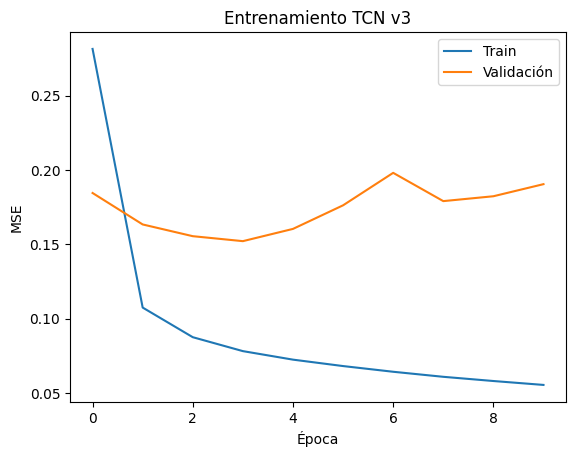

In [39]:
import matplotlib.pyplot as plt

plt.plot(hist_train_v3, label="Train")
plt.plot(hist_val_v3, label="Validación")
plt.xlabel("Época")
plt.ylabel("MSE")
plt.title("Entrenamiento TCN v3")
plt.legend()
plt.show()

In [40]:
modelo_v3.eval()
s = datos.splits["test"]

with torch.no_grad():
    y_esc_test = modelo_v3(
        torch.from_numpy(s.pasado).to(device),
        torch.from_numpy(s.futuro).to(device)
    ).cpu().numpy()

y_pred_test = datos.invertir(y_esc_test)
metricas_test = evaluar(datos.y_original("test"), y_pred_test)

metricas_test

{'demanda_MAE': 81533.97678912395,
 'precio_MAE': 83.8177522070082,
 'demanda_RMSE': 102851.70446479098,
 'precio_RMSE': 124.09858953819659,
 'demanda_MAPE_%': 2.692470551368342,
 'precio_MAPE_%': 19.57474185121872,
 'demanda_R2': 0.8679458671026541,
 'precio_R2': 0.8516834962140559}

In [41]:
resultados_finales = pd.DataFrame({
    "Métrica": [
        "MAE demanda", "RMSE demanda", "MAPE demanda (%)", "R² demanda",
        "MAE precio", "RMSE precio", "MAPE precio (%)", "R² precio"
    ],
    "Validación": [
        73762.63, 100190.61, 2.49, 0.857,
        57.56, 102.13, 27.30, 0.563
    ],
    "Prueba": [
        81533.98, 102851.70, 2.69, 0.868,
        83.82, 124.10, 19.57, 0.852
    ]
})

resultados_finales

,Métrica,Validación,Prueba
0,MAE demanda,73762.630,81533.980
1,RMSE demanda,100190.610,102851.700
2,MAPE demanda (%),2.490,2.690
3,R² demanda,0.857,0.868
4,MAE precio,57.560,83.820
5,RMSE precio,102.130,124.100
6,MAPE precio (%),27.300,19.570
7,R² precio,0.563,0.852


## Conclusiones

Se desarrollaron distintas configuraciones de una red convolucional temporal (TCN) utilizando los mismos tensores, particiones y procedimiento de evaluación definidos para la fase 2 del proyecto. La selección de la arquitectura se realizó exclusivamente sobre la partición de validación, manteniendo la partición de prueba fuera del proceso de decisión.

La configuración seleccionada fue la TCN v3, que utiliza las últimas 24 representaciones producidas por la red convolucional junto con las últimas 24 horas observadas y las covariables futuras. Esta configuración obtuvo la menor pérdida MSE de validación entre las variantes principales evaluadas.

En validación, la TCN obtuvo un MAPE de 2.49 % para demanda y 27.30 % para precio. El resultado de demanda supera la línea base semanal de 3.83 %, mientras que el precio no supera la línea base diaria de 20.34 %. Por tanto, la arquitectura muestra una mejora clara para el pronóstico de demanda, pero mantiene dificultades para generalizar el comportamiento del precio durante 2025-S2.

Una vez seleccionada la arquitectura se evaluó sobre la partición de prueba. En este periodo se obtuvo un MAPE de 2.69 % para demanda y 19.57 % para precio, con R² de 0.868 y 0.852, respectivamente. El desempeño del precio mejora considerablemente respecto a validación, especialmente en MAPE y R².

La diferencia entre validación y prueba es consistente con el análisis previo del proyecto, donde 2025-S2 fue identificado como un periodo particularmente difícil debido al cambio estructural del perfil intradía del precio. En consecuencia, los resultados de ambas particiones deben reportarse conjuntamente y no utilizar el mejor desempeño de prueba para modificar nuevamente la arquitectura.

En conjunto, la TCN presenta un desempeño estable para la demanda y una mayor sensibilidad a los cambios de régimen del precio. Estos resultados permiten utilizarla posteriormente en la comparación común con las arquitecturas RNN, GRU, LSTM y Transformer.